Finding low-altitude ARTEMIS passes and correlating with known lunar surface anomalies using SVM data from Tsunakawa et al. (2015). 

Start with the familiar 4 Dec 2013 THB data from Sawyer: 

In [5]:
import pyspedas

trange = ['2013-12-04/00:00', '2013-12-04/12:00']
loaded = pyspedas.projects.themis.state(probe='b', trange=trange)
print(loaded)

22-Oct-26 17:16:10: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf


['thb_pos', 'thb_vel', 'thb_spin_initial_delta_phi', 'thb_spin_idpu_spinper', 'thb_spin_segflags', 'thb_spin_ecl_initial_delta_phi', 'thb_spin_ecl_idpu_spinper', 'thb_spin_ecl_segflags', 'thb_pos_gse', 'thb_pos_gsm', 'thb_vel_gse', 'thb_vel_gsm', 'thb_pos_sel', 'thb_pos_sse', 'thb_vel_sel', 'thb_vel_sse']


File already containse SEL (moon-fixed selenographic position) for SVM, so do not need to convert again. Check units and centre quickly:

In [7]:
import numpy as np
from pyspedas import get_data, time_string

d = get_data('thb_pos_sel')
t, xyz = d.times, d.y
r = np.linalg.norm(xyz, axis=1)

print(xyz[:3]) #first few positions
print(r.min(), r.max()) #closest and furthest distance of approach
print(time_string(t[r.argmin()])) #time at which the closest approach occurs

[[-1399.0868    1502.8933     -14.914508]
 [-1281.8687    1547.2798     -14.522243]
 [-1161.8776    1588.2611     -14.074393]]
1752.193 18314.56
2013-12-04 00:12:00.000000


Closest approach is 1752 km at 00:12, so altitude is approx 14.8 km (consistent with Sawyer altitude plot). Furthest point is 18315 km for elliptical orbit.

In [8]:
print(np.diff(t[:4])) #check time between samples / s

alt = r - 1737.4
lat = np.degrees(np.arcsin(xyz[:, 2] / r))
lon = np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0])) % 360

i = r.argmin()
print(lon[i], lat[i], alt[i]) #lowest sample lat, long and alt
print(time_string(t[alt < 100][[0, -1]]))  #first and last sample below 100 km

[60. 60. 60.]
85.109375 -0.25907627 14.792969
['2013-12-04 00:06:00.000000', '2013-12-04 00:18:00.000000']


Timestamps are UT; probe spent 12 minutes below 100 km from 00:06 to 00:18. Sampling at 1 position per minute.

First look at the global map for the 30 km file. Angular grid resolution is 0.5 degrees. Can calculate field at given location using Bcal.90 program (Fortan). 

Can use reshape to rearrange list into table and create SVM map at 30km altitude:

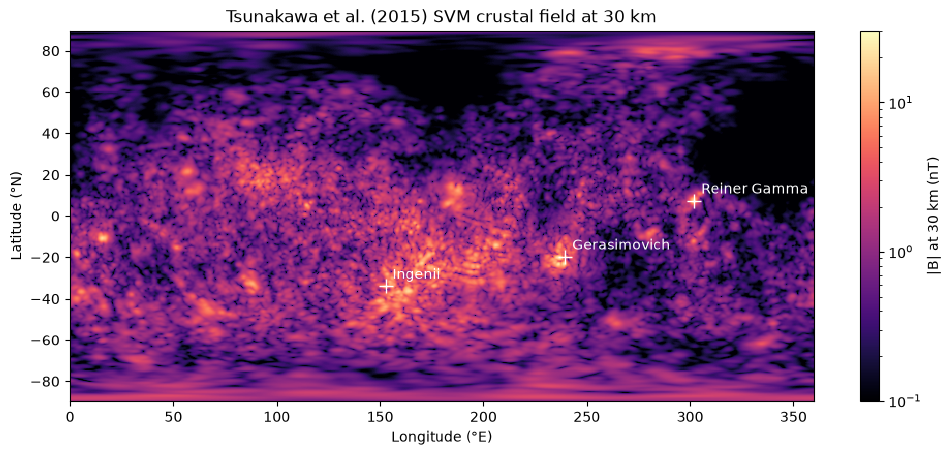

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

folder = '/Users/yulun/artemis-lunar-plasma/data/globalSVM20150511/'
d = np.loadtxt(folder + 'LunarSVM_030_05_v01.dat', skiprows=12) #258480 rows and 6 columns (lon, lat, Be, Bn, Br, Bt) with 12 lines of header text

nlat, nlon = 359, 720
lon = d[:, 0].reshape(nlat, nlon) 
lat = d[:, 1].reshape(nlat, nlon)
Bt  = d[:, 5].reshape(nlat, nlon)

fig, ax = plt.subplots(figsize=(12, 6))
pc = ax.pcolormesh(lon, lat, np.clip(Bt, 0.1, None),
                   norm=LogNorm(vmin=0.1, vmax=30), cmap='magma', shading='auto')
fig.colorbar(pc, ax=ax, label='|B| at 30 km (nT)', shrink=0.8)

#plot anomalies for reference
for name, (lo, la) in {'Reiner Gamma': (302, 7.5),
                       'Gerasimovich': (239.6, -19.6),
                       'Ingenii': (152.6, -33.8)}.items():
    ax.plot(lo, la, 'w+', ms=10)
    ax.annotate(name, (lo, la), xytext=(5, 5), textcoords='offset points', color='w')

ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
ax.set_aspect('equal')
ax.set_title('Tsunakawa et al. (2015) SVM crustal field at 30 km')
plt.show()

Create function for loading probe track to return position data. L1 state file only gives ARTEMIS position once per minute, so can interpolate to once evert 3s to match FGM data (spin resolution) using cubic spline fit.

Input: probe and time window

Output: times, longitude, latitude, altitude

In [32]:
import numpy as np
import pyspedas
from pyspedas import get_data
from scipy.interpolate import CubicSpline

R_M = 1737.4   #lunar radius / km

def load_track(probe, trange, t_out=None):
    """
    ARTEMIS position over the Moon: returns t, lon (deg E), lat (deg), alt (km).
    If t_out is given, the position is splined onto those times.
    """
    name = f'th{probe}_pos_sel'
    pyspedas.projects.themis.state(probe=probe, trange=trange, varnames=[name], time_clip=True)
    d = get_data(name)
    t, xyz = d.times, d.y

    if t_out is not None:
        xyz = CubicSpline(t, xyz, axis=0)(t_out)   #smooth curve through 1-min samples
        t = t_out

    #convert to lon, lat, alt
    r   = np.linalg.norm(xyz, axis=1)
    lat = np.degrees(np.arcsin(xyz[:, 2] / r))
    lon = np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0])) % 360
    return t, lon, lat, r - R_M

Can also write function to return lon, lat, alt for given moment:

In [37]:
from pyspedas import time_double, time_string

def where_is(probe, time, pad=600):
    """
    Position of an ARTEMIS probe at one moment: returns lon (deg E), lat (deg), alt (km).
    """
    t0 = time_double(time)
    tr = [time_string(t0 - pad), time_string(t0 + pad)] #10 minutes either side
    t, lon, lat, alt = load_track(probe, tr, t_out=np.array([t0]))
    return lon[0], lat[0], alt[0]

Test on Sawyer pass:

25-Oct-26 19:56:06: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
25-Oct-26 19:56:07: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf


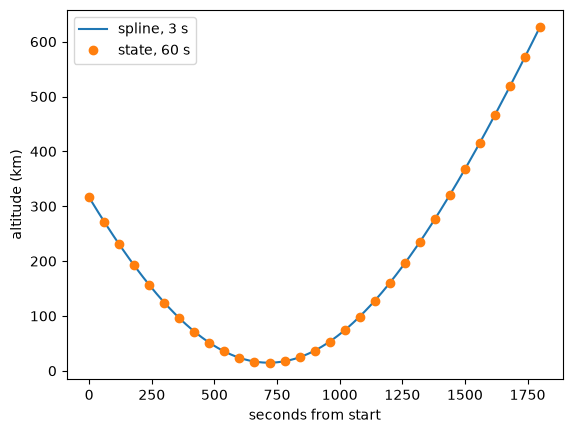

minimum altitudes (km): 14.792969 , 14.786457242907545


In [36]:
import matplotlib.pyplot as plt

tr = ['2013-12-04/00:00', '2013-12-04/00:30']
t1, lon1, lat1, alt1 = load_track('b', tr) #raw 1-minute samples
t_fine = np.arange(t1[0], t1[-1], 3.0) #every 3 s
t2, lon2, lat2, alt2 = load_track('b', tr, t_out=t_fine) #splined

plt.plot(t2 - t2[0], alt2, label='spline, 3 s')
plt.plot(t1 - t1[0], alt1, 'o', alpha=1, label='state, 60 s')
plt.xlabel('seconds from start'); plt.ylabel('altitude (km)'); plt.legend()
plt.show()
print("minimum altitudes (km):", alt1.min(), ",", alt2.min())

Clipped time to 30 minute minima. Spine follows orbit data successfully and minimum state sample and spline minima agree to within 10 m.

To feed splined positions into svm_field, must first install pyshtools:

In [40]:
%pip install pyshtools

25-Oct-26 22:08:22: /Users/yulun/miniforge3/lib/python3.12/pty.py:95: DeprecationWarning: This process (pid=70742) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.7 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyshtools]/3 [pyshtools]

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Loading cell first:

Need SHTOOLS (Fortran 95 library) to handle arrays, so import pyshtools. 

In [46]:
import pyshtools as sh
shc_file = '/Users/yulun/artemis-lunar-plasma/data/globalSVM20150511/LunarSVM_SHC_v01.dat'

#read data into 2D array of shape (101925, 4)
c = np.loadtxt(shc_file, skiprows=10) #columns: n, m, g, h
n, m = c[:, 0].astype(int), c[:, 1].astype(int) #convert to integers since need to use n, m as array positions

#Tsunakawa calculates spherical harmonic coefficients up to n=450
coeffs = np.zeros((2, 451, 451)) #create empty container array of the right size

#coeffs[i (0=g, 1=h), n (degree, row), m (order, column)]
coeffs[0, n, m] = c[:, 2] #g, i.e. coefficients for cos(m/phi)
coeffs[1, n, m] = c[:, 3] #h, i.e. coefficients for sin(m/phi)

#use Schmidt norm'isation and define Condon-Shortley factor as 1, consistent with Tsunakawa
svm = sh.SHMagCoeffs.from_array(coeffs, r0=R_M, normalization='schmidt', csphase=1)

#evaluate at specific point instead of full grid
def svm_field(lon, lat, alt):
    """
    SVM crustal field at lon (deg E), lat (deg), alt (km). Returns Be, Bn, Br in nT.
    """
    out = np.atleast_2d(svm.expand(lon=lon, lat=lat, a=R_M + np.asarray(alt))) #np.atleast_2d: ensures output is (1, 3) instead of (3,), so obtain arrays
    Br, Btheta, Bphi = out.T
    return Bphi, -Btheta, Br #-Btheta required for South coordinate

svm_expand: converts to spherical coords, computes every associated Legendre functions, computes cos(m\phi) and si(m\phi) terms to calculate B_r, B_theta and B_phi.

SHMagCoeffs is a container holding the coefficient array with the information needed to interpret it. 

np.atleast_2d: unpacks data into arrays instead of plain numbers

Plotting the Sawyer event for 4 Dec 2013 00:00–00:30 UT:

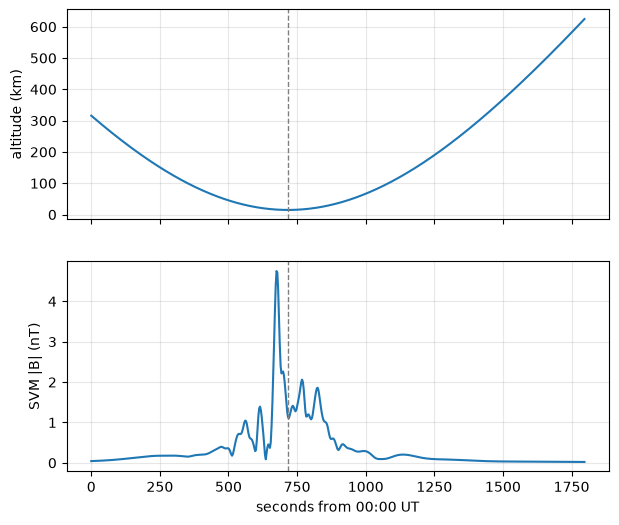

In [48]:
Be, Bn, Br = svm_field(lon2, lat2, alt2)
Bt_svm = np.sqrt(Be**2 + Bn**2 + Br**2)

ts = t2 - t2[0] #seconds from 00:00 UT
t_peri = ts[np.argmin(alt2)] #time at which periapsis occurs 

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax1.plot(t2 - t2[0], alt2)
ax1.set_ylabel('altitude (km)')
ax2.plot(t2 - t2[0], Bt_svm)
ax2.set_ylabel('SVM |B| (nT)')
ax2.set_xlabel('seconds from 00:00 UT')

#add gridlines and periapsis time
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.3)
    ax.axvline(t_peri, color='grey', ls='--', lw=1)     

plt.show()

Results: B peak occurs approx 45 seconds before periapsis. Max B comparable to SW field. Can resolve around features of 15 km across. To understand this lag, plot measured field using FGM data: 

Load FGM data for same period:

In [49]:
fgm_vars = pyspedas.projects.themis.fgm(probe='b', trange=tr, level='l2', time_clip=True)
print(fgm_vars)

d = get_data('thb_fgs_gse') #spin resolution to match 3s track
t_fgm, B_gse = d.times, d.y
Bt_obs = np.linalg.norm(B_gse, axis=1) #measured field strength at each time in GSE

26-Oct-26 15:57:00: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2013/
26-Oct-26 15:57:02: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf


['thb_fgs_btotal', 'thb_fgs_gse', 'thb_fgs_gsm', 'thb_fgs_dsl', 'thb_fgl_btotal', 'thb_fgl_gse', 'thb_fgl_gsm', 'thb_fgl_dsl', 'thb_fgl_ssl', 'thb_fgh_btotal', 'thb_fgh_gse', 'thb_fgh_gsm', 'thb_fgh_dsl', 'thb_fgh_ssl']


Plot measured B: 

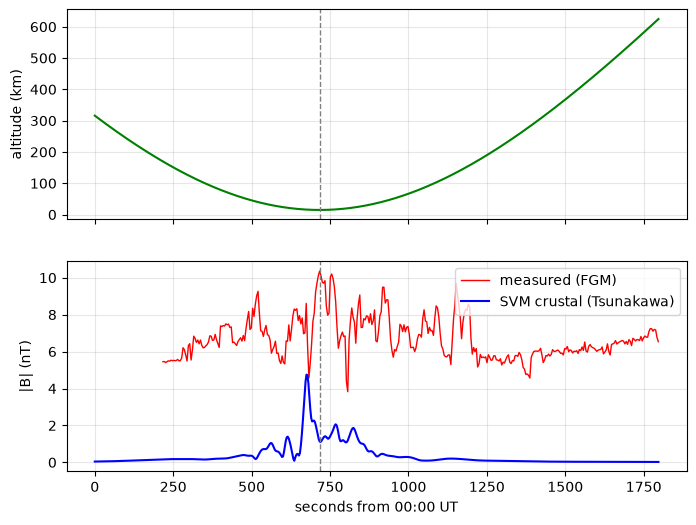

In [62]:
ts = t2 - t2[0]
t_peri = ts[np.argmin(alt2)]

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

ax1.plot(ts, alt2, color='green')
ax1.set_ylabel('altitude (km)')

ax2.plot(t_fgm - t2[0], Bt_obs, color='red', lw=1, label='measured (FGM)')
ax2.plot(ts, Bt_svm, color='blue', label='SVM crustal (Tsunakawa)')
ax2.set_ylabel('|B| (nT)')
ax2.set_xlabel('seconds from 00:00 UT')
ax2.legend()

for ax in (ax1, ax2):
    ax.grid(True, alpha=0.3)
    ax.axvline(t_peri, color='grey', ls='--', lw=1)

plt.show()

Observations:
- SW baseline fluctuates at arund 6 nT (i.e. not constant)
- Field enhancement over wider window than SVM prediction
- at SVM peak, measured B decreases... why?
- Sharp drop at around 800s (thin current sheet?)

From Sawyer:
- 00:05:45 – 00:08:00 (345-480): THB and THC measure same field (ions peak at approx 1keV, consistent with SW electrons), baseline SW
- 00:08:00 – 00:11:10 (480-670): open field lines connected to surface, electron heating
- 00:11:10 – 11:12:00 (670-720): closed field lines
- 00:12:00 - 00:16:00 (720-960): open field lines

Conclusion: enhanced window matches Sawyer connection interval, i.e. enhancement correlated to period over which THB was magnetically connected to the lunar surface.

Add SZA to check terminator position relative to probe:

In [63]:
pyspedas.projects.themis.state(probe='b', trange=tr, varnames=['thb_pos_sse'], time_clip=True)
d = get_data('thb_pos_sse')
xyz_sse = CubicSpline(d.times, d.y, axis=0)(t2)          # SSE position on the same 3 s times
sza = np.degrees(np.arccos(xyz_sse[:, 0] / np.linalg.norm(xyz_sse, axis=1)))

26-Oct-26 16:07:00: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf


Plot SZA:

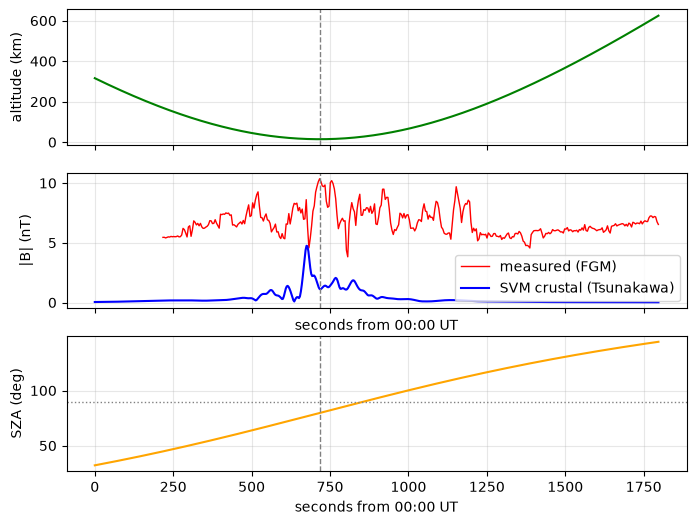

In [67]:
ts = t2 - t2[0]
t_peri = ts[np.argmin(alt2)]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 6))

ax1.plot(ts, alt2, color='green')
ax1.set_ylabel('altitude (km)')

ax2.plot(t_fgm - t2[0], Bt_obs, color='red', lw=1, label='measured (FGM)')
ax2.plot(ts, Bt_svm, color='blue', label='SVM crustal (Tsunakawa)')
ax2.set_ylabel('|B| (nT)')
ax2.set_xlabel('seconds from 00:00 UT')
ax2.legend()

ax3.plot(ts, sza, color = 'orange')
ax3.axhline(90, color='grey', ls=':', lw=1) #terminator
ax3.set_ylabel('SZA (deg)')
ax3.set_xlabel('seconds from 00:00 UT')

for ax in (ax1, ax2, ax3):
    ax.grid(True, alpha=0.3)
    ax.axvline(t_peri, color='grey', ls='--', lw=1)

plt.show()

Confirms event occurs on sunlit side close to terminator, in accordance with Sawyer. This means that the interaction is weaker since the SW grazes lunar surface.

THC sat upstream in undisturbed SW. Check THC data and check for agreement with THB for baseline period:

In [68]:
# THC magnetic field
pyspedas.projects.themis.fgm(probe='c', trange=tr, level='l2', time_clip=True)
d = get_data('thc_fgs_gse')
t_thc, Bc_gse = d.times, d.y
Bt_thc = np.linalg.norm(Bc_gse, axis=1)

# where THC was, relative to the Moon (SSE, km)
pyspedas.projects.themis.state(probe='c', trange=tr, varnames=['thc_pos_sse'], time_clip=True)
pos_c = get_data('thc_pos_sse').y
print('THC position at start (km, SSE):', pos_c[0])
print('THC distance from Moon (lunar radii):', np.linalg.norm(pos_c[0]) / R_M)

26-Oct-26 16:44:20: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2013/
26-Oct-26 16:44:22: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
26-Oct-26 16:44:23: time_clip: thc_fgh_btotal has no data in requested range
26-Oct-26 16:44:23: time_clip: thc_fgh_gse has no data in requested range
26-Oct-26 16:44:23: time_clip: thc_fgh_gsm has no data in requested range
26-Oct-26 16:44:23: time_clip: thc_fgh_dsl has no data in requested range
26-Oct-26 16:44:23: time_clip: thc_fgh_ssl has no data in requested range
26-Oct-26 16:44:23: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l1/state/2013/thc_l1_state_20131204.cdf to themis_data/thc/l1/state/2013/thc_l1_state_20131204.cdf
26-Oct-26 16:44:24: Download of themis_data/thc/l1/state/2013/thc_l1_state_20131204.cdf complete, 0.571 MB in 1.1 sec (0.499 MB/sec) (transfer_normal)


THC position at start (km, SSE): [15948.937   6215.941   3469.8696]
THC distance from Moon (lunar radii): 10.052711


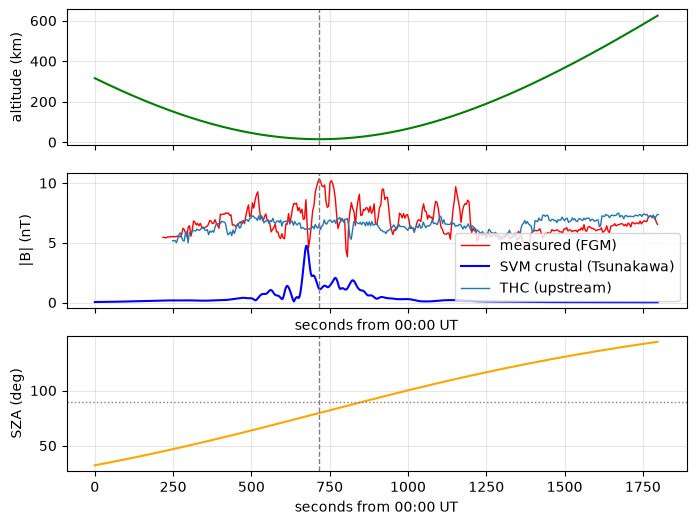

In [69]:
ts = t2 - t2[0]
t_peri = ts[np.argmin(alt2)]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 6))

ax1.plot(ts, alt2, color='green')
ax1.set_ylabel('altitude (km)')

ax2.plot(t_fgm - t2[0], Bt_obs, color='red', lw=1, label='measured (FGM)')
ax2.plot(ts, Bt_svm, color='blue', label='SVM crustal (Tsunakawa)')
ax2.plot(t_thc - t2[0], Bt_thc, color='C0', lw=1, label='THC (upstream)')
ax2.set_ylabel('|B| (nT)')
ax2.set_xlabel('seconds from 00:00 UT')
ax2.legend()

ax3.plot(ts, sza, color = 'orange')
ax3.axhline(90, color='grey', ls=':', lw=1) #terminator
ax3.set_ylabel('SZA (deg)')
ax3.set_xlabel('seconds from 00:00 UT')

for ax in (ax1, ax2, ax3):
    ax.grid(True, alpha=0.3)
    ax.axvline(t_peri, color='grey', ls='--', lw=1)

plt.show()

Data agree up to approx 480s (measured B at 6-7 nT). THB departs from THB between approx 480 and 1050s, in agreement with Sawyer's connected interval. After approx 1250s, THB measurements are approx 1 nT lower than THC (wake effect?)

Next we measure the THB-THC time shift from the data to correct for time lag, so we can superpose the field strength measurements for the two different regimes.

best shift: 14.0 s   correlation: 0.862


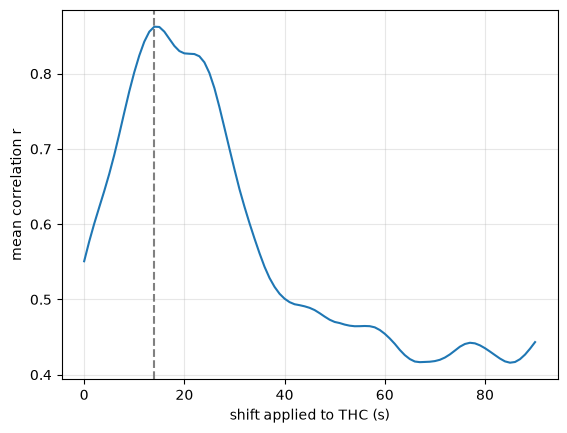

In [70]:
t0 = t2[0] #set 00:00 UT as the shared clock

def on_grid(t, B, tg):
    """
    Field components interpolated onto times tg (seconds from 00:00).
    Times outside the data are returned as NaN.
    """
    return np.column_stack([np.interp(tg, t - t0, B[:, i], left=np.nan, right=np.nan) for i in range(3)])

grid = np.arange(300, 480, 1.0) #THB in the solar wind, every 1 s
Bb = on_grid(t_fgm, B_gse, grid) #THB on established grid

lags = np.arange(0, 91, 1.0) #try time shifts from 0–90 s
score = []
for L in lags:
    Bc = on_grid(t_thc, Bc_gse, grid - L) #THC data shifted by L seconds
    ok = np.all(np.isfinite(Bb), axis=1) & np.all(np.isfinite(Bc), axis=1)
    if ok.sum() < 60: #discard if overlap too small
        score.append(np.nan)
        continue
    r = [np.corrcoef(Bb[ok, i], Bc[ok, i])[0, 1] for i in range(3)]
    score.append(np.mean(r)) #take average over x, y, z

score = np.array(score)
best = lags[np.nanargmax(score)]
print('best shift:', best, 's   correlation:', np.nanmax(score).round(3))

plt.plot(lags, score)
plt.axvline(best, color='grey', ls='--')
plt.xlabel('shift applied to THC (s)'); plt.ylabel('mean correlation r')
plt.grid(True, alpha=0.3); plt.show()

Best correlation is for 14 second shift. Load variables for plotting:

In [71]:
shift = best #14 s
t_thc_shifted = t_thc + shift

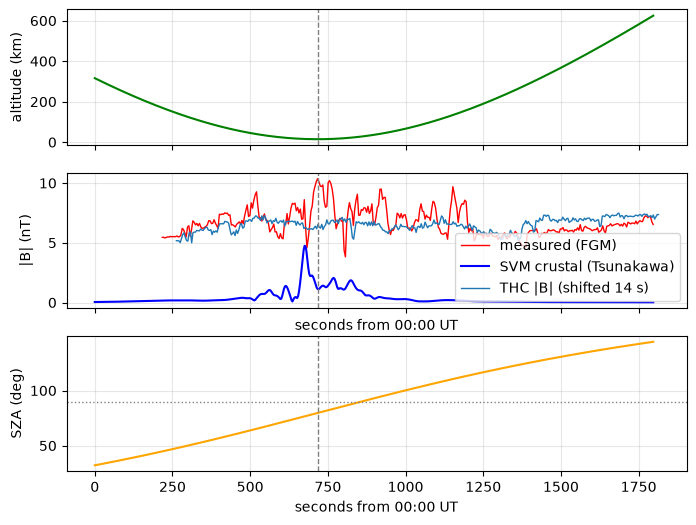

In [72]:
ts = t2 - t2[0]
t_peri = ts[np.argmin(alt2)]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 6))

ax1.plot(ts, alt2, color='green')
ax1.set_ylabel('altitude (km)')

ax2.plot(t_fgm - t2[0], Bt_obs, color='red', lw=1, label='measured (FGM)')
ax2.plot(ts, Bt_svm, color='blue', label='SVM crustal (Tsunakawa)')
ax2.plot(t_thc_shifted - t0, Bt_thc, color='C0', lw=1, label=f'THC |B| (shifted {shift:.0f} s)')
ax2.set_ylabel('|B| (nT)')
ax2.set_xlabel('seconds from 00:00 UT')
ax2.legend()

ax3.plot(ts, sza, color = 'orange')
ax3.axhline(90, color='grey', ls=':', lw=1) #terminator
ax3.set_ylabel('SZA (deg)')
ax3.set_xlabel('seconds from 00:00 UT')

for ax in (ax1, ax2, ax3):
    ax.grid(True, alpha=0.3)
    ax.axvline(t_peri, color='grey', ls='--', lw=1)

plt.show()

Some mismatch during baseline interval. Zoom into SW interval and compare components:

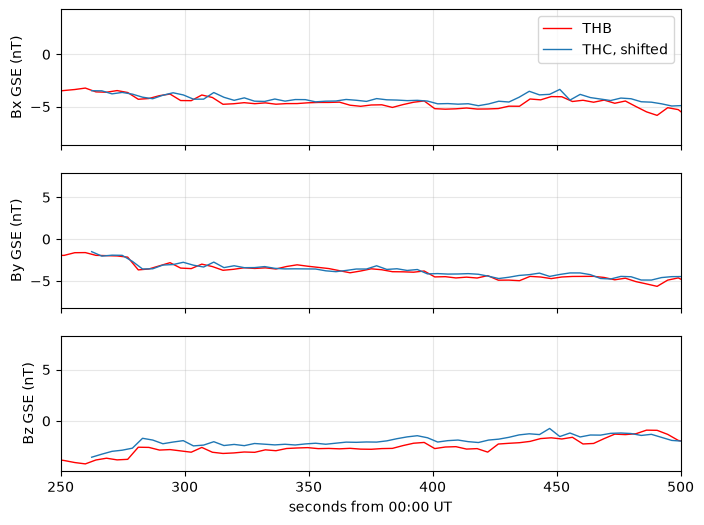

In [73]:
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
for i, lab in enumerate(['Bx', 'By', 'Bz']):
    axs[i].plot(t_fgm - t0, B_gse[:, i], color='r', lw=1, label='THB')
    axs[i].plot(t_thc_shifted - t0, Bc_gse[:, i], color='C0', lw=1, label='THC, shifted')
    axs[i].set_ylabel(f'{lab} GSE (nT)')
    axs[i].grid(True, alpha=0.3)
axs[0].legend()
axs[-1].set_xlim(250, 500)                       # zoom to the solar-wind interval
axs[-1].set_xlabel('seconds from 00:00 UT')
plt.show()

In [79]:
Bc_on = on_grid(t_thc_shifted, Bc_gse, grid) #shifted THC on the same 1s grid as THB
diff = Bb - Bc_on
ok = np.all(np.isfinite(diff), axis=1) #filter out where both probes had real data
print('mean difference (nT):', diff[ok].mean(axis=0).round(2))
print('rms scatter (nT):   ', diff[ok].std(axis=0).round(2))

mean difference (nT): [-0.38 -0.18 -0.61]
rms scatter (nT):    [0.21 0.25 0.2 ]


Shift captures variation successfully. There also exists a steady offset (calibration error?) and rms scatter. Pick out the baseline period (300-420 s) and use components to find the average (offset) and the spread (noise floor):

In [78]:
quiet = (grid >= 300) & (grid <= 420)
ok_q = ok & quiet

offset = diff[ok_q].mean(axis=0) #steady offset (average)
noise = diff[ok_q].std(axis=0) #noise floor per component (standard deviation)

print('offset (nT):', offset.round(2), '& standard deviation (nT):', noise.round(2))

offset (nT): [-0.34 -0.14 -0.63] & standard deviation (nT): [0.2  0.27 0.16]


Subtract THC from THB to obtain difference in B field due to Moon, to set up for comparision against SVM to deduce plasma interactions:

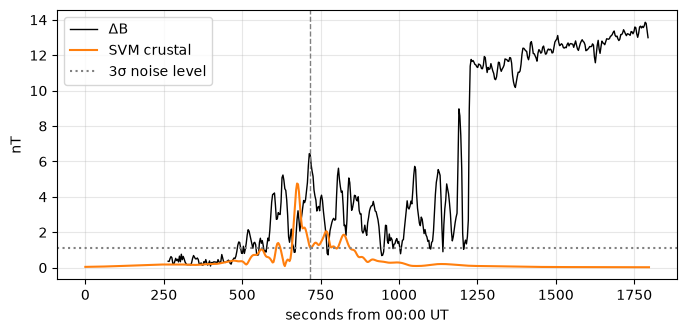

In [80]:
B_thb = on_grid(t_fgm, B_gse, ts) #THB on the 3s track times
B_bg  = on_grid(t_thc_shifted, Bc_gse, ts) + offset #solar-wind background at THB
dB = B_thb - B_bg #the Moon's effect (GSE, nT)

dB_mag = np.linalg.norm(dB, axis=1)
sigma_mag = np.sqrt(np.sum(noise**2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ts, dB_mag, color='k', lw=1, label='ΔB')
ax.plot(ts, Bt_svm, color='C1', lw=1.5, label='SVM crustal')
ax.axhline(3 * sigma_mag, color='grey', ls=':', label='3σ noise level')
ax.axvline(t_peri, color='grey', ls='--', lw=1)
ax.set_xlabel('seconds from 00:00 UT'); ax.set_ylabel('nT')
ax.grid(True, alpha=0.3); ax.legend()
plt.show()

What is happening after 1200? Let's attempt to diagnose by looking at components of both probes over a longer window:

31-Oct-26 21:10:46: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2013/
31-Oct-26 21:10:49: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
31-Oct-26 21:10:49: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2013/
31-Oct-26 21:10:51: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
31-Oct-26 21:10:52: time_clip: thc_fgh_btotal has no data in requested range
31-Oct-26 21:10:52: time_clip: thc_fgh_gse has no data in requested range
31-Oct-26 21:10:52: time_clip: thc_fgh_gsm has no data in requested range
31-Oct-26 21:10:52: time_clip: thc_fgh_dsl has no data in requested range
31-Oct-26 21:10:52: time_clip: thc_fgh_ssl has no data in requested range


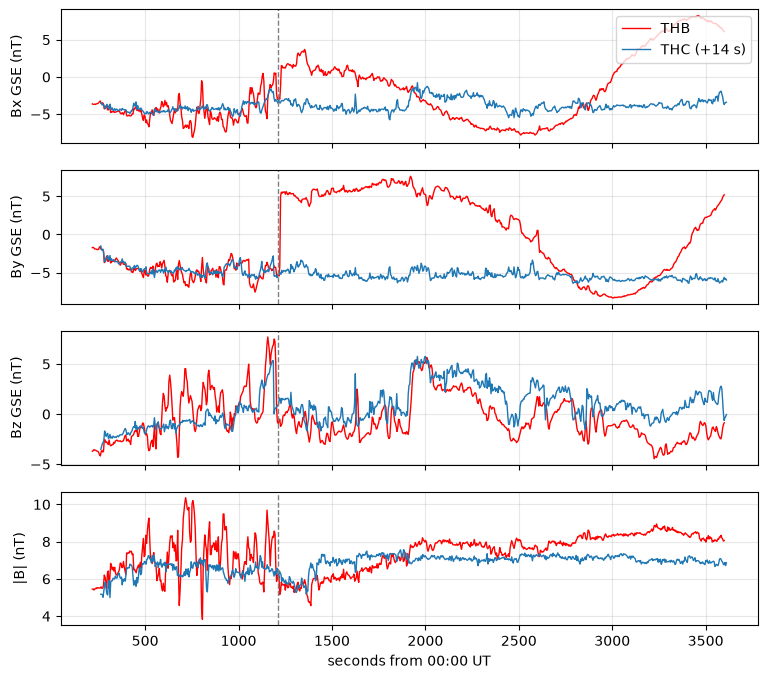

In [90]:
tr_long = ['2013-12-04/00:00', '2013-12-04/01:00']
pyspedas.projects.themis.fgm(probe=['b', 'c'], trange=tr_long, level='l2', time_clip=True)
b_l = get_data('thb_fgs_gse')
c_l = get_data('thc_fgs_gse')

fig, axs = plt.subplots(4, 1, sharex=True, figsize=(9, 8))
for i, lab in enumerate(['Bx', 'By', 'Bz']):
    axs[i].plot(b_l.times - t0, b_l.y[:, i], color='r', lw=1, label='THB')
    axs[i].plot(c_l.times + shift - t0, c_l.y[:, i], color='C0', lw=1, label=f'THC (+{shift:.0f} s)')
    axs[i].set_ylabel(f'{lab} GSE (nT)')
axs[3].plot(b_l.times - t0, np.linalg.norm(b_l.y, axis=1), color='r', lw=1, label='THB')
axs[3].plot(c_l.times + shift - t0, np.linalg.norm(c_l.y, axis=1), color='C0', lw=1, label='THC')
axs[3].set_ylabel('|B| (nT)'); axs[3].set_xlabel('seconds from 00:00 UT')
for ax in axs:
    ax.grid(True, alpha=0.3); ax.axvline(1210, color='grey', ls='--', lw=1)
axs[0].legend(loc='upper right')
plt.show()

THB field appears to flip in x-y plane, whilst THC remains unaffected. Why could this be?

To diagnose, look at angle between THB and THC and also ratio (for B magnitude). 

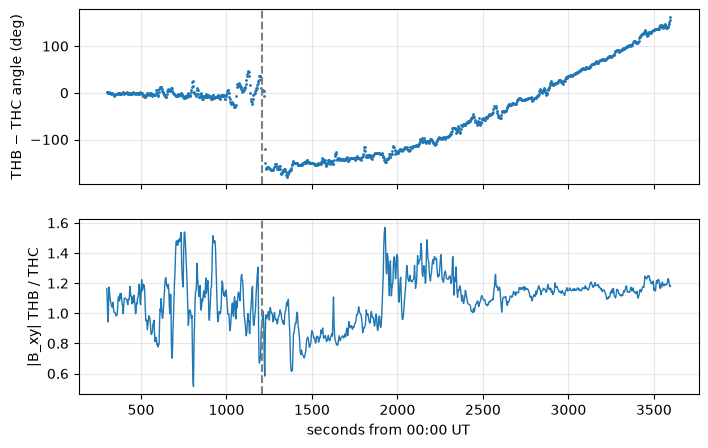

In [99]:
grid_long = np.arange(300, 3600, 3.0)
Bb_L = on_grid(b_l.times, b_l.y, grid_long)
Bc_L = on_grid(c_l.times + shift, c_l.y, grid_long)

ang_b = np.degrees(np.arctan2(Bb_L[:, 1], Bb_L[:, 0])) #direction in the x–y plane
ang_c = np.degrees(np.arctan2(Bc_L[:, 1], Bc_L[:, 0]))
dphi = (ang_b - ang_c + 180) % 360 - 180
ratio = np.hypot(Bb_L[:, 0], Bb_L[:, 1]) / np.hypot(Bc_L[:, 0], Bc_L[:, 1])

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(grid_long, dphi, '.', ms=2); axs[0].set_ylabel('THB − THC angle (deg)')
axs[1].plot(grid_long, ratio, lw=1);    axs[1].set_ylabel('|B_xy| THB / THC')
axs[1].set_xlabel('seconds from 00:00 UT')
for ax in axs: ax.grid(True, alpha=0.3); ax.axvline(1210, color='grey', ls='--')
plt.show()

Check shadow entry / exit times:

In [94]:
tr3 = ['2013-12-04/00:00', '2013-12-04/03:00']
pyspedas.projects.themis.state(probe='b', trange=tr3, varnames=['thb_pos_sse'], time_clip=True)
p = get_data('thb_pos_sse')
shadow = (p.y[:, 0] < 0) & (np.hypot(p.y[:, 1], p.y[:, 2]) < R_M)
ts_p = p.times - t0
for k in np.flatnonzero(np.diff(shadow.astype(int))):
    print('enters' if shadow[k + 1] else 'exits', 'shadow at ~', ts_p[k + 1], 's')

31-Oct-26 21:52:57: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf


enters shadow at ~ 1260.0 s
exits shadow at ~ 4920.0 s


Plot over full shadow period:

31-Oct-26 22:17:35: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2013/
31-Oct-26 22:17:38: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
31-Oct-26 22:17:38: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2013/
31-Oct-26 22:17:39: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf


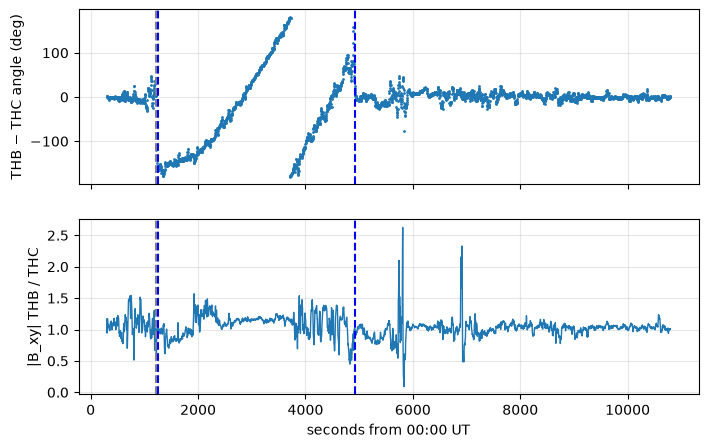

In [102]:
pyspedas.projects.themis.fgm(probe=['b', 'c'], trange=tr3, level='l2', time_clip=True)
b_l = get_data('thb_fgs_gse')
c_l = get_data('thc_fgs_gse')

grid_long = np.arange(300, 10800, 3.0)
Bb_L = on_grid(b_l.times, b_l.y, grid_long)
Bc_L = on_grid(c_l.times + shift, c_l.y, grid_long)

ang_b = np.degrees(np.arctan2(Bb_L[:, 1], Bb_L[:, 0])) #direction in the x–y plane
ang_c = np.degrees(np.arctan2(Bc_L[:, 1], Bc_L[:, 0]))
dphi = (ang_b - ang_c + 180) % 360 - 180
ratio = np.hypot(Bb_L[:, 0], Bb_L[:, 1]) / np.hypot(Bc_L[:, 0], Bc_L[:, 1])

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(grid_long, dphi, '.', ms=2); axs[0].set_ylabel('THB − THC angle (deg)')
axs[1].plot(grid_long, ratio, lw=1);    axs[1].set_ylabel('|B_xy| THB / THC')
axs[1].set_xlabel('seconds from 00:00 UT')
for ax in axs: ax.grid(True, alpha=0.3); ax.axvline(1210, color='grey', ls='--'); ax.axvline(4920, color='blue', ls='--'); ax.axvline(1260, color='blue', ls='--')
plt.show()

Conclusion: spin-plane components rotate due to eclipse.

***Validations, visualisations and numerical checks below:***

**Check coefficient model and svm_field function:**

Write a function to check that coefficient model reproduces published maps: 

In [83]:
def compare_map(d, alt, lmax):
    """
    Evaluate the SVM coefficients on a global grid at some altitude alt and compare with the corresponding map file
    """
    g = svm.expand(a=R_M + alt, lmax=lmax) #evaluate coefficients on global grid
    step = 180 / (2 * (lmax + 1)) #lmax=719 gives spacing 0.125 (30 km)and lmax=899 gives 0.1 (surface)
    i = np.rint((90 - d[:, 1]) / step).astype(int) #grid row
    j = np.rint(d[:, 0] / step).astype(int) #grid column

    #pick out model values:
    model = np.column_stack([g.phi.data[i, j], -g.theta.data[i, j], g.rad.data[i, j], g.total.data[i, j]])
    for k, name in enumerate(['Be', 'Bn', 'Br', 'Bt']):
        obs = d[:, 2 + k]
        r = np.corrcoef(model[:, k], obs)[0, 1]
        print(f'{name}: r = {r:.4f}   mean diff = {np.std(model[:, k] - obs):.3f} nT')
    return model

#load published maps 
d30 = np.loadtxt(folder + 'LunarSVM_030_05_v01.dat', skiprows=12)
d0  = np.loadtxt(folder + 'LunarSVM_000_02_v01.dat', skiprows=12)
m30 = compare_map(d30, 30.0, 719)
m0  = compare_map(d0, 0.0, 899)

Be: r = 1.0000   mean diff = 0.003 nT
Bn: r = 1.0000   mean diff = 0.003 nT
Br: r = 1.0000   mean diff = 0.003 nT
Bt: r = 1.0000   mean diff = 0.006 nT
Be: r = 0.8950   mean diff = 2.642 nT
Bn: r = 0.9024   mean diff = 3.040 nT
Br: r = 0.8814   mean diff = 4.754 nT
Bt: r = 0.9513   mean diff = 3.670 nT


Very good agreement for 30 km altitude and good agreement for surface. Increased rms could be due to edge effect of cells and reduced smoothing compared with at altitude. 

Since no lon / lat is specified, svm.expand(a=R_M + alt, lmax=lmax) computes field on a regular global field at radius a.

g is a grid object containing several 2D arrays in .data, including:
- g.rad.data (radial component of B)
- g.theta.data (polar component)
- g.phi.data (azimuthal component)
- g.total.data (magnitude)

Also test previously defined svm_field(lon, lat, alt) function against 30 km altitude map:

In [84]:
rng = np.random.default_rng(0) #random number generator with seed 0
s = d30[rng.choice(len(d30), 3000, replace=False)] #take random rows from Tsunakawa 30 km map
Be, Bn, Br = svm_field(s[:, 0], s[:, 1], np.full(len(s), 30.0))
print('max |diff| (nT):', [np.abs(a - s[:, k]).max().round(3) for a, k in ((Be, 2), (Bn, 3), (Br, 4))])

max |diff| (nT): [np.float64(0.009), np.float64(0.012), np.float64(0.027)]


**Check coordinate transforms:**

Define new function to check SEL to local coord transform: 

In [85]:
def sel2enr(B, lon, lat):
    """
    Rotate vectors from Moon-fixed Cartesian (SEL) into local east, north, up at (lon, lat)
    """
    phi, lam = np.radians(lon), np.radians(lat)
    e = np.stack([-np.sin(phi), np.cos(phi), np.zeros_like(phi)], axis=-1)
    n = np.stack([-np.sin(lam) * np.cos(phi), -np.sin(lam) * np.sin(phi), np.cos(lam)],       axis=-1)
    r = np.stack([ np.cos(lam) * np.cos(phi),  np.cos(lam) * np.sin(phi), np.sin(lam)],       axis=-1)
    return np.sum(B * e, axis=1), np.sum(B * n, axis=1), np.sum(B * r, axis=1)

In [86]:
#Load published B_positions from running Bcal on Positions.dat
b = np.loadtxt(folder + 'B_Positions_supplied.rst', skiprows=1) # Bcal: Lon Lat Alt Bx By Bz Be Bn Br Bt
Be, Bn, Br = sel2enr(b[:, 3:6], b[:, 0], b[:, 1]) #slice columns 3, 4, 5 for Bx, By, Bz, and also lon and lat

#pair rotated components with columns in B_Positions_supplied:
print('max |diff| vs Bcal (nT):', [np.abs(x - b[:, k]).max().round(4) for x, k in ((Be, 6), (Bn, 7), (Br, 8))])

# sanity check for the SEL axes seen from (0N, 0E)
print(sel2enr(np.eye(3), np.zeros(3), np.zeros(3)))

max |diff| vs Bcal (nT): [np.float64(0.0011), np.float64(0.001), np.float64(0.0012)]
(array([0., 1., 0.]), array([0., 0., 1.]), array([1., 0., 0.]))


Can also test SPEDAS transformations.

Check rotation first:

In [89]:
from pyspedas.projects.themis import gse2sse, sse2sel

#load Sawyer interval in GSE and SEL
pyspedas.projects.themis.state(probe='b', trange=tr, varnames=['thb_pos_gse', 'thb_pos_sel'], time_clip=True)

gse2sse('thb_pos_gse', 'thb_pos_sse_test', variable_type='pos') #rotate and move origin to the Moon and write as new variable
sse2sel('thb_pos_sse_test', 'thb_pos_sel_test') # rotate into Moon-fixed axes

mine  = get_data('thb_pos_sel_test').y
truth = get_data('thb_pos_sel').y
gap = np.linalg.norm(mine - truth, axis=1)
print('max position difference (km):', gap.max().round(3))
print('angular variation (deg):', np.degrees(gap / np.linalg.norm(truth, axis=1)).max().round(4))

31-Oct-26 20:48:17: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
31-Oct-26 20:48:17: Transforming slp_sun_pos to GSE
31-Oct-26 20:48:17: ['gei', 'gse']
31-Oct-26 20:48:17: /Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/pyspedas/cotrans_tools/cotrans_lib.py:130: DeprecationWarning: numpy.fix is deprecated. Use numpy.trunc instead, which is faster and follows the Array API standard.
  jj = 365 * (iyear - 1900) + np.fix((iyear - 1901) / 4) + idoy

31-Oct-26 20:48:17: Running transformation: subgei2gse
31-Oct-26 20:48:17: Setting coordinate system for slp_sun_pos_gse
31-Oct-26 20:48:17: Output variable: slp_sun_pos_gse
31-Oct-26 20:48:17: Transforming slp_lun_pos to GSE
31-Oct-26 20:48:17: ['gei', 'gse']
31-Oct-26 20:48:17: Running transformation: subgei2gse
31-Oct-26 20:48:17: Setting coordinate system for slp_lun_pos_gse
31-Oct-26 20:48:17: Output variable: slp_lun_pos_gse
31-Oct-26 20:48:18: tinterpol (linear) was applied to: gse2sse_off

max position difference (km): 0.159
angular variation (deg): 0.0039


Variation is small, so we are using coord transformation tools as expected.

Can also apply rotation to magnetic field:

In [88]:
gse2sse('thb_fgs_gse', 'thb_fgs_sse')
sse2sel('thb_fgs_sse', 'thb_fgs_sel')

B_sel = get_data('thb_fgs_sel').y
print('|B| change (nT):', np.abs(np.linalg.norm(B_sel, axis=1) - np.linalg.norm(B_gse, axis=1)).max())

30-Oct-26 14:18:18: File is current: themis_data/slp/l1/eph/2013/slp_l1_eph_20131204_v01.cdf
30-Oct-26 14:18:18: File is current: themis_data/slp/l1/eph/2013/slp_l1_eph_20131205_v01.cdf
30-Oct-26 14:18:19: Setting coordinate system for slp_sun_pos
30-Oct-26 14:18:19: Setting coordinate system for slp_sun_vel
30-Oct-26 14:18:19: Setting coordinate system for slp_sun_att_x
30-Oct-26 14:18:19: Setting coordinate system for slp_sun_att_z
30-Oct-26 14:18:19: Setting coordinate system for slp_lun_pos
30-Oct-26 14:18:19: Setting coordinate system for slp_lun_vel
30-Oct-26 14:18:19: Setting coordinate system for slp_lun_att_x
30-Oct-26 14:18:19: Setting coordinate system for slp_lun_att_z
30-Oct-26 14:18:19: Transforming slp_sun_pos to GSE
30-Oct-26 14:18:19: ['gei', 'gse']
30-Oct-26 14:18:19: /Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/pyspedas/cotrans_tools/cotrans_lib.py:130: DeprecationWarning: numpy.fix is deprecated. Use numpy.trunc instead, which is faster and f

|B| change (nT): 8.135970510636525e-07
